In [ ]:
{
 "cells": [],
 "metadata": {},
 "nbformat": 4,
 "nbformat_minor": 5
}

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Spatial domain
L = 2 * np.pi

# Velocity domain
v_min = -6.0
v_max = 6.0

# Grid resolution
Nx = 64
Nv = 64

# Perturbation
alpha = 0.01
k = 1.0

# Create grids
x = np.linspace(0, L, Nx, endpoint=False)
v = np.linspace(v_min, v_max, Nv)

dx = L / Nx
dv = (v_max - v_min) / (Nv - 1)

# Phase-space mesh
X, V = np.meshgrid(x, v, indexing="ij")

print(f"Nx = {Nx}")
print(f"Nv = {Nv}")
print(f"dx = {dx:.5f}")
print(f"dv = {dv:.5f}")
print(f"Phase-space points = {Nx * Nv}")

Nx = 64
Nv = 64
dx = 0.09817
dv = 0.19048
Phase-space points = 4096


In [3]:
# Maxwellian equilibrium
f_equilibrium = (
    1 / np.sqrt(2 * np.pi)
    * np.exp(-V**2 / 2)
)

# Small spatial perturbation
f = f_equilibrium * (
    1 + alpha * np.cos(k * X)
)

print("f shape:", f.shape)
print("f min:", f.min())
print("f max:", f.max())

f shape: (64, 64)
f min: 6.015124021325053e-09
f max: 0.4011084859468086


In [4]:
# Number density
density = np.sum(f, axis=1) * dv

print("Density shape:", density.shape)
print("Density min:", density.min())
print("Density max:", density.max())

Density shape: (64,)
Density min: 0.9899999989783075
Density max: 1.0099999989576673


In [5]:
# Uniform positive background
ion_density = 1.0

# Charge density in normalized units
rho = ion_density - density

print("Charge density min:", rho.min())
print("Charge density max:", rho.max())

Charge density min: -0.009999998957667344
Charge density max: 0.010000001021692517


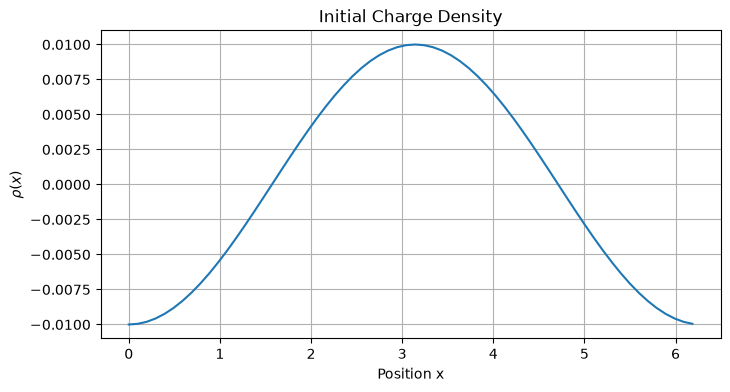

In [6]:
plt.figure(figsize=(8, 4))

plt.plot(x, rho)

plt.xlabel("Position x")
plt.ylabel(r"$\rho(x)$")
plt.title("Initial Charge Density")

plt.grid(True)
plt.show()

In [7]:
# Fourier wave numbers
kx = 2 * np.pi * np.fft.fftfreq(Nx, d=dx)

# Fourier transform of charge density
rho_hat = np.fft.fft(rho)

# Allocate Fourier-space potential
phi_hat = np.zeros_like(rho_hat, dtype=complex)

# Solve Poisson equation in Fourier space
for i in range(Nx):
    if kx[i] != 0:
        phi_hat[i] = rho_hat[i] / (kx[i] ** 2)
    else:
        phi_hat[i] = 0.0

# Transform back to physical space
phi = np.real(np.fft.ifft(phi_hat))

print("Potential shape:", phi.shape)

Potential shape: (64,)


In [8]:
# Electric field in Fourier space
E_hat = -1j * kx * phi_hat

# Transform back to physical space
E = np.real(np.fft.ifft(E_hat))

print("Electric field shape:", E.shape)
print("E min:", E.min())
print("E max:", E.max())

Electric field shape: (64,)
E min: -0.00999999998967986
E max: 0.00999999998967986


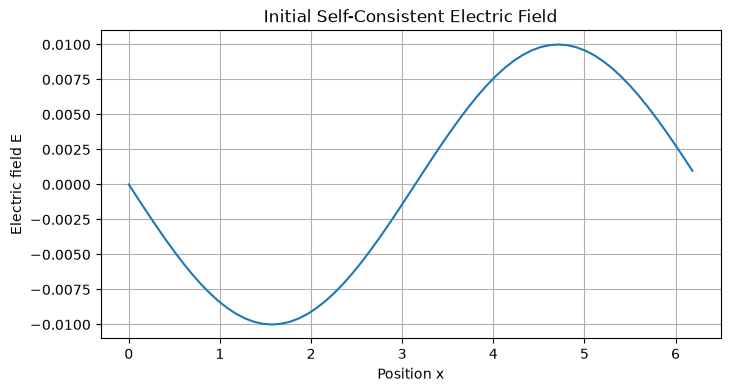

In [9]:
plt.figure(figsize=(8, 4))

plt.plot(x, E)

plt.xlabel("Position x")
plt.ylabel("Electric field E")
plt.title("Initial Self-Consistent Electric Field")

plt.grid(True)
plt.show()

In [10]:
def spectral_derivative_x(f, kx):
    """
    Spectral derivative with respect to x.

    f has shape (Nx, Nv).
    """
    f_hat = np.fft.fft(f, axis=0)
    df_dx_hat = 1j * kx[:, None] * f_hat
    df_dx = np.real(np.fft.ifft(df_dx_hat, axis=0))

    return df_dx

In [11]:
def finite_difference_v(f, dv):
    """
    Centered finite-difference derivative with respect to velocity.
    """
    df_dv = np.zeros_like(f)

    df_dv[:, 1:-1] = (
        f[:, 2:] - f[:, :-2]
    ) / (2 * dv)

    # One-sided differences at velocity boundaries
    df_dv[:, 0] = (
        f[:, 1] - f[:, 0]
    ) / dv

    df_dv[:, -1] = (
        f[:, -1] - f[:, -2]
    ) / dv

    return df_dv

In [12]:
def vlasov_rhs(f, V, E, kx, dv):
    """
    Right-hand side of the normalized 1D1V Vlasov equation.
    """

    df_dx = spectral_derivative_x(f, kx)
    df_dv = finite_difference_v(f, dv)

    rhs = (
        -V * df_dx
        + E[:, None] * df_dv
    )

    return rhs

In [13]:
def calculate_electric_field(f, dv, kx):
    """
    Calculate the self-consistent electric field
    from the distribution function.
    """

    density = np.sum(f, axis=1) * dv

    ion_density = 1.0
    rho = ion_density - density

    rho_hat = np.fft.fft(rho)

    phi_hat = np.zeros_like(rho_hat, dtype=complex)

    nonzero = kx != 0
    phi_hat[nonzero] = rho_hat[nonzero] / (kx[nonzero] ** 2)

    E_hat = -1j * kx * phi_hat

    E = np.real(np.fft.ifft(E_hat))

    return E, rho, phi_hat

In [14]:
E, rho, phi_hat = calculate_electric_field(
    f,
    dv,
    kx
)

print("Maximum |E| =", np.max(np.abs(E)))

Maximum |E| = 0.00999999998967986


In [15]:
def rk4_step(f, dt, V, kx, dv):
    """
    One fourth-order Runge-Kutta time step.
    The electric field is recalculated self-consistently
    during each sub-step.
    """

    E1, _, _ = calculate_electric_field(f, dv, kx)
    k1 = vlasov_rhs(f, V, E1, kx, dv)

    f2 = f + 0.5 * dt * k1
    E2, _, _ = calculate_electric_field(f2, dv, kx)
    k2 = vlasov_rhs(f2, V, E2, kx, dv)

    f3 = f + 0.5 * dt * k2
    E3, _, _ = calculate_electric_field(f3, dv, kx)
    k3 = vlasov_rhs(f3, V, E3, kx, dv)

    f4 = f + dt * k3
    E4, _, _ = calculate_electric_field(f4, dv, kx)
    k4 = vlasov_rhs(f4, V, E4, kx, dv)

    f_new = f + (dt / 6.0) * (
        k1 + 2*k2 + 2*k3 + k4
    )

    return f_new

In [16]:
dt = 0.01
t_final = 20.0

num_steps = int(t_final / dt)

print("Time steps:", num_steps)

Time steps: 2000


In [17]:
# Reset to initial condition
f_current = f.copy()

times = []
electric_field_amplitude = []

for step in range(num_steps):

    t = step * dt

    E, _, _ = calculate_electric_field(
        f_current,
        dv,
        kx
    )

    times.append(t)
    electric_field_amplitude.append(
        np.max(np.abs(E))
    )

    f_current = rk4_step(
        f_current,
        dt,
        V,
        kx,
        dv
    )

    if step % 200 == 0:
        print(
            f"Step {step:4d}/{num_steps}, "
            f"t = {t:.2f}, "
            f"max|E| = {np.max(np.abs(E)):.6e}"
        )

Step    0/2000, t = 0.00, max|E| = 1.000000e-02
Step  200/2000, t = 2.00, max|E| = 1.835719e-03
Step  400/2000, t = 4.00, max|E| = 2.493305e-04
Step  600/2000, t = 6.00, max|E| = 8.089749e-06
Step  800/2000, t = 8.00, max|E| = 9.585325e-06
Step 1000/2000, t = 10.00, max|E| = 1.690762e-06
Step 1200/2000, t = 12.00, max|E| = 4.377191e-08
Step 1400/2000, t = 14.00, max|E| = 4.672456e-08
Step 1600/2000, t = 16.00, max|E| = 1.452553e-05
Step 1800/2000, t = 18.00, max|E| = 5.979292e-06


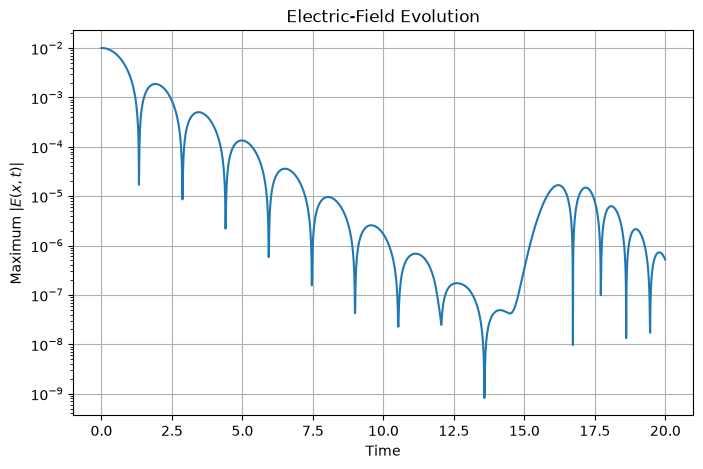

In [18]:
plt.figure(figsize=(8, 5))

plt.semilogy(
    times,
    electric_field_amplitude
)

plt.xlabel("Time")
plt.ylabel(r"Maximum $|E(x,t)|$")
plt.title("Electric-Field Evolution")

plt.grid(True)

plt.show()

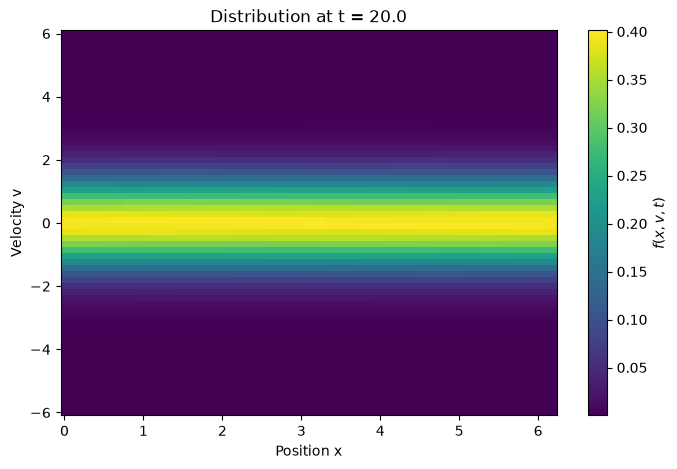

In [19]:
plt.figure(figsize=(8, 5))

plt.pcolormesh(
    x,
    v,
    f_current.T,
    shading="auto"
)

plt.xlabel("Position x")
plt.ylabel("Velocity v")
plt.title(f"Distribution at t = {t_final}")

plt.colorbar(label=r"$f(x,v,t)$")

plt.show()